# Q//Horizon 2026: Quantum vs. Classical Pulsar Classification

**Kubits Team:** Zeyad Mohamed Nada, Omar Eslam, Youssef Sallam *(see `docs/TEAM.md` for full contributions)*
**End-to-End Reproducible Benchmark & Statistical Verification Notebook**

In [1]:
import os, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

if not Path("results").exists():
    if not Path("qhorizon-2026").exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/zeyadmsn07/qhorizon-2026.git"], check=True)
    os.chdir("qhorizon-2026")

RESULTS_DIR = Path("results")
RES_DIR = RESULTS_DIR / "full" if (RESULTS_DIR / "full" / "verdicts.json").exists() else RESULTS_DIR / "fast"
print(f"Loaded verified artifacts from: {RES_DIR.resolve()}")


Loaded verified artifacts from: C:\Users\MSI\Desktop\qhorizon-2026\results\full


## 1. Main Benchmark, Parameter Accounting & Mechanical Verdicts (`N_train = 500`)


# Statistical Verdicts & Two-Level Bootstrap CIs (`results/full`)

Rule (`margin = 0.01` PR-AUC, 95% CI across seeds x stratified test resamples): **Supported** (`CI > 0` and `|delta| > 0.01`), **Practically tied** (`CI` inside `[-0.01, +0.01]`), **Contradicted** (`CI < 0` and `|delta| > 0.01`), **Inconclusive** otherwise.

## 1. Hypothesis Verdicts
| ID | Comparison (A vs. B) | Delta PR-AUC | 95% Two-Level CI | Wilcoxon p (min p) | Verdict |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **H1a** | Tiny-MLP (41p) vs. Q2-QuantumKernel (8q) | `+0.0130` | `[+0.0047, +0.0217]` | 0.0039 (min 0.0020) | **Supported** |
| **H1b** | Tiny-MLP (41p) vs. Q1-VQC (Bipartite_SignLinear_41p) | `+0.0144` | `[+0.0060, +0.0232]` | 0.0020 (min 0.0020) | **Supported** |
| **H1c** | Q2-QuantumKernel (8q) vs. RandomForest | `+0.0101` | `[+0.0027, +0.0189]` | 0.0020 (min 0.0020) | **Supported** |
| **H2a** | VQC_bipartite_L2 vs. VQC_none_L2 | `+0.0110` | `[-0.0006, +0.0227]` | 0.0371 (min 0.0020) | **Inconclusive** |
| **H2b** | VQC_bipartite_L2 vs. VQC_ring_L2 | `+0.0120` | `[+0.0025, +0.0225]` | 0.0020 (min 0.0020) | **Supported** |
| **H3** | 4q_AmplitudePlusNorm_L4 vs. 3q_Amplitude_L5 | `+0.2450` | `[+0.1909, +0.2885]` | 0.0020 (min 0.0020) | **Supported** |
| **H4a** | N=100 Q2-QuantumKernel vs. RBF-SVM (tied) | `-0.0460` | `[-0.0847, -0.0142]` | 0.0098 (min 0.0020) | **Contradicted** |
| **H4b_2000** | Shots=2000 vs. Analytic (tied) | `-0.0007` | `[-0.0015, +0.0000]` | 0.0059 (min 0.0020) | **Practically tied** |
| **H4b_500** | Shots=500 vs. Analytic (tied) | `-0.0011` | `[-0.0028, +0.0005]` | 0.1602 (min 0.0020) | **Practically tied** |
| **H4b_100** | Shots=100 vs. Analytic (tied) | `-0.0068` | `[-0.0112, -0.0031]` | 0.0020 (min 0.0020) | **Inconclusive** |

## 2. Pairwise Comparison vs. Best Classical (`Tiny-MLP (41p)`)
| Model | Mean PR-AUC | 95% Two-Level CI | Collapse | Delta vs. Best Classical | Paired 95% CI | Verdict |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Dummy** | `0.0917` | `[0.0917, 0.0917]` | 10/10 | `-0.8330` | `[-0.8573, -0.8067]` | Contradicted |
| **LogReg** | `0.9184` | `[0.8891, 0.9453]` | 0/10 | `-0.0062` | `[-0.0187, +0.0031]` | Inconclusive |
| **RBF-SVM** | `0.9227` | `[0.8940, 0.9459]` | 0/10 | `-0.0020` | `[-0.0079, +0.0039]` | Practically tied |
| **RandomForest** | `0.9016` | `[0.8721, 0.9293]` | 0/10 | `-0.0231` | `[-0.0363, -0.0110]` | Contradicted |
| **Tiny-MLP (41p)** | `0.9246` | `[0.8983, 0.9490]` | 0/10 | `+0.0000` | `[+0.0000, +0.0000]` | Reference |
| **Q1-VQC (Bipartite_SignLinear_41p)** | `0.9102` | `[0.8817, 0.9356]` | 0/10 | `-0.0144` | `[-0.0232, -0.0060]` | Contradicted |
| **Q1-VQC (Ring L=2, Fragile v1)** | `0.8860` | `[0.8521, 0.9169]` | 0/10 | `-0.0386` | `[-0.0541, -0.0229]` | Contradicted |
| **Q2-QuantumKernel (8q)** | `0.9116` | `[0.8819, 0.9370]` | 0/10 | `-0.0130` | `[-0.0217, -0.0047]` | Contradicted |


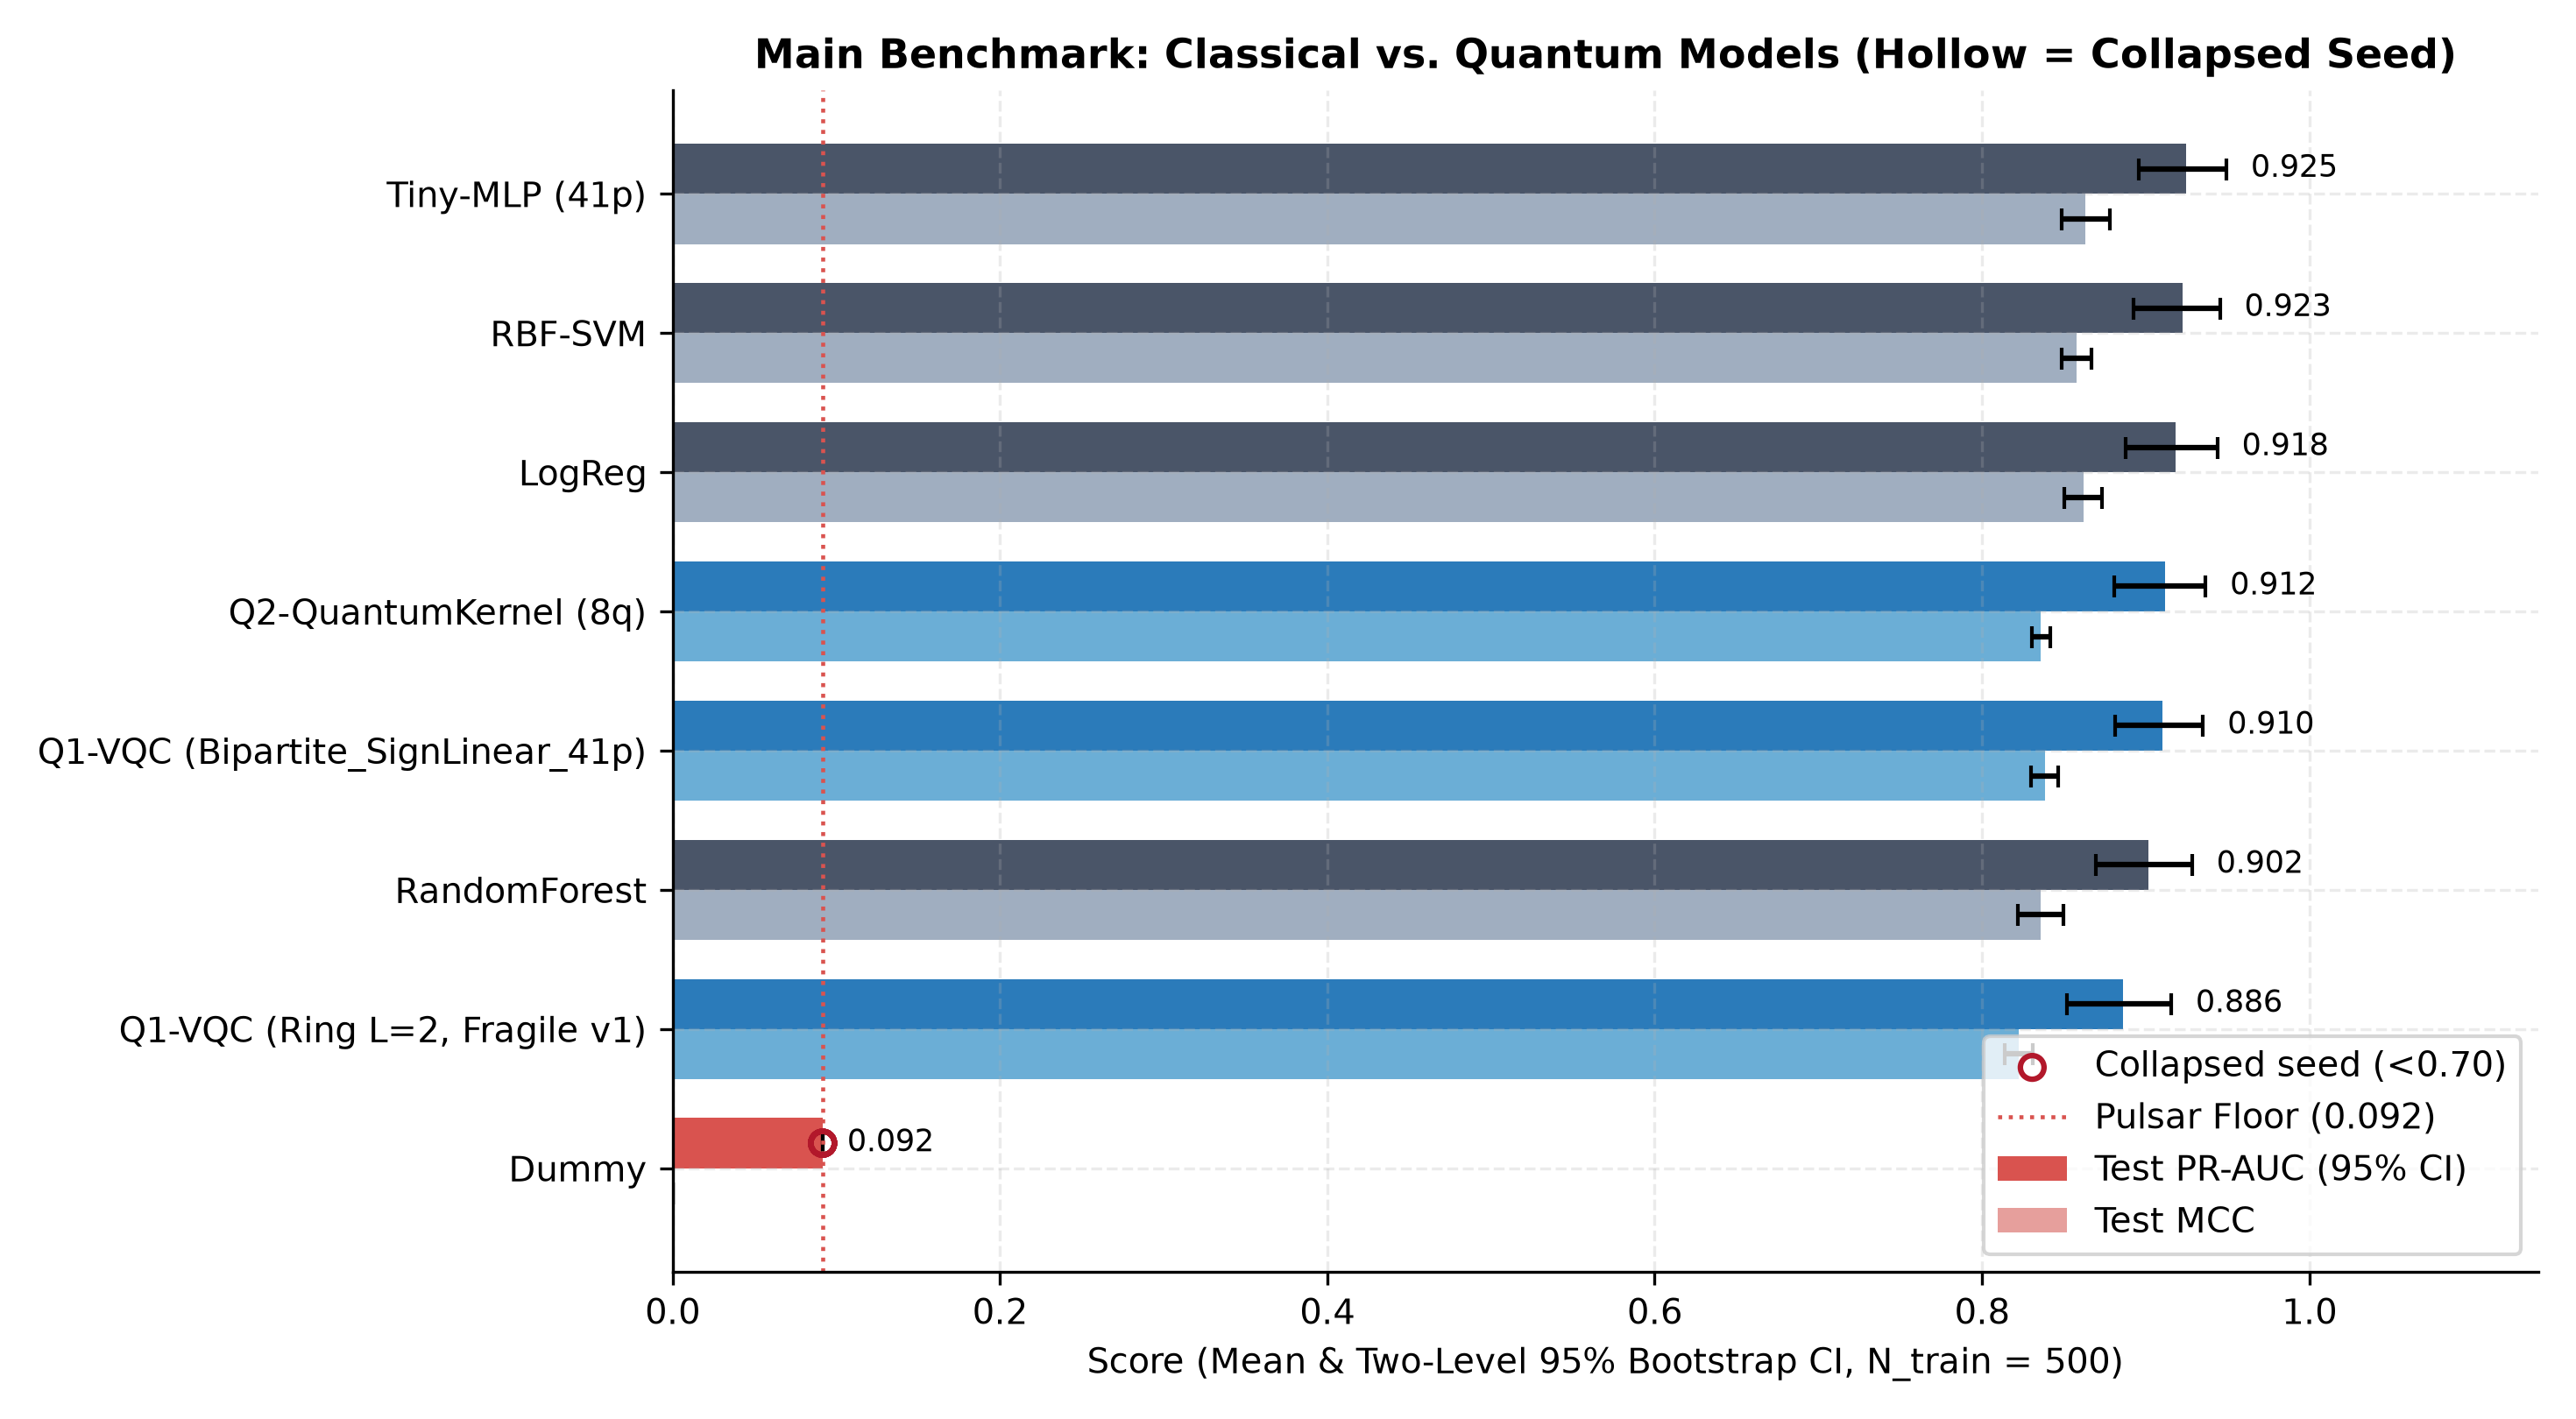

In [2]:
display(Markdown((RES_DIR / "verdicts.md").read_text(encoding="utf-8")))
display(Image(filename=str(RES_DIR / "main_benchmark.png")))


## 2. VQC Stability, Symmetry Breaking & Encoding Ablations


# VQC Stability & Symmetry-Breaking Study (`C:/Users/MSI/Desktop/qhorizon-2026/results/full`)

**Pre-stated headline selection rule:** Highest mean validation PR-AUC across disjoint tune_seeds (tie-break: lower tune val std); test set never consulted.

**Validation-selected headline VQC:** `Bipartite_SignLinear_41p` (`tune val PR-AUC = 0.9022`)

| Variant | Tune Val PR-AUC | Test PR-AUC | 95% Bootstrap CI | Collapse Rate | Init Grad Norm | Trainable Params |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| `Ring_L2_Baseline` | `0.8611` | `0.8860` | `[0.8518, 0.9155]` | 0/10 | `0.963` | 34 |
| `Init_WideNormal_0.5` | `0.8845` | `0.8894` | `[0.8529, 0.9183]` | 0/10 | `0.603` | 34 |
| `Init_Uniform_Pi` | `0.8670` | `0.8598` | `[0.8158, 0.8943]` | 0/10 | `0.260` | 34 |
| `SignAware_Offset_Pi2` | `0.8627` | `0.8854` | `[0.8486, 0.9143]` | 0/10 | `0.291` | 34 |
| `Readout_Linear8_41p` | `0.8725` | `0.8869` | `[0.8512, 0.9156]` | 0/10 | `1.659` | 41 |
| `Readout_SingleZ0` | `0.8707` | `0.8782` | `[0.8402, 0.9127]` | 0/10 | `0.399` | 34 |
| `Epochs100_Patience20` | `0.8677` | `0.8869` | `[0.8492, 0.9161]` | 0/10 | `1.012` | 34 |
| `Restarts_k3_ValSelected` | `0.8621` | `0.8884` | `[0.8545, 0.9186]` | 0/10 | `0.976` | 34 |
| `Bipartite_SignLinear_41p` | `0.9022` | `0.9102` | `[0.8813, 0.9349]` | 0/10 | `0.566` | 41 |


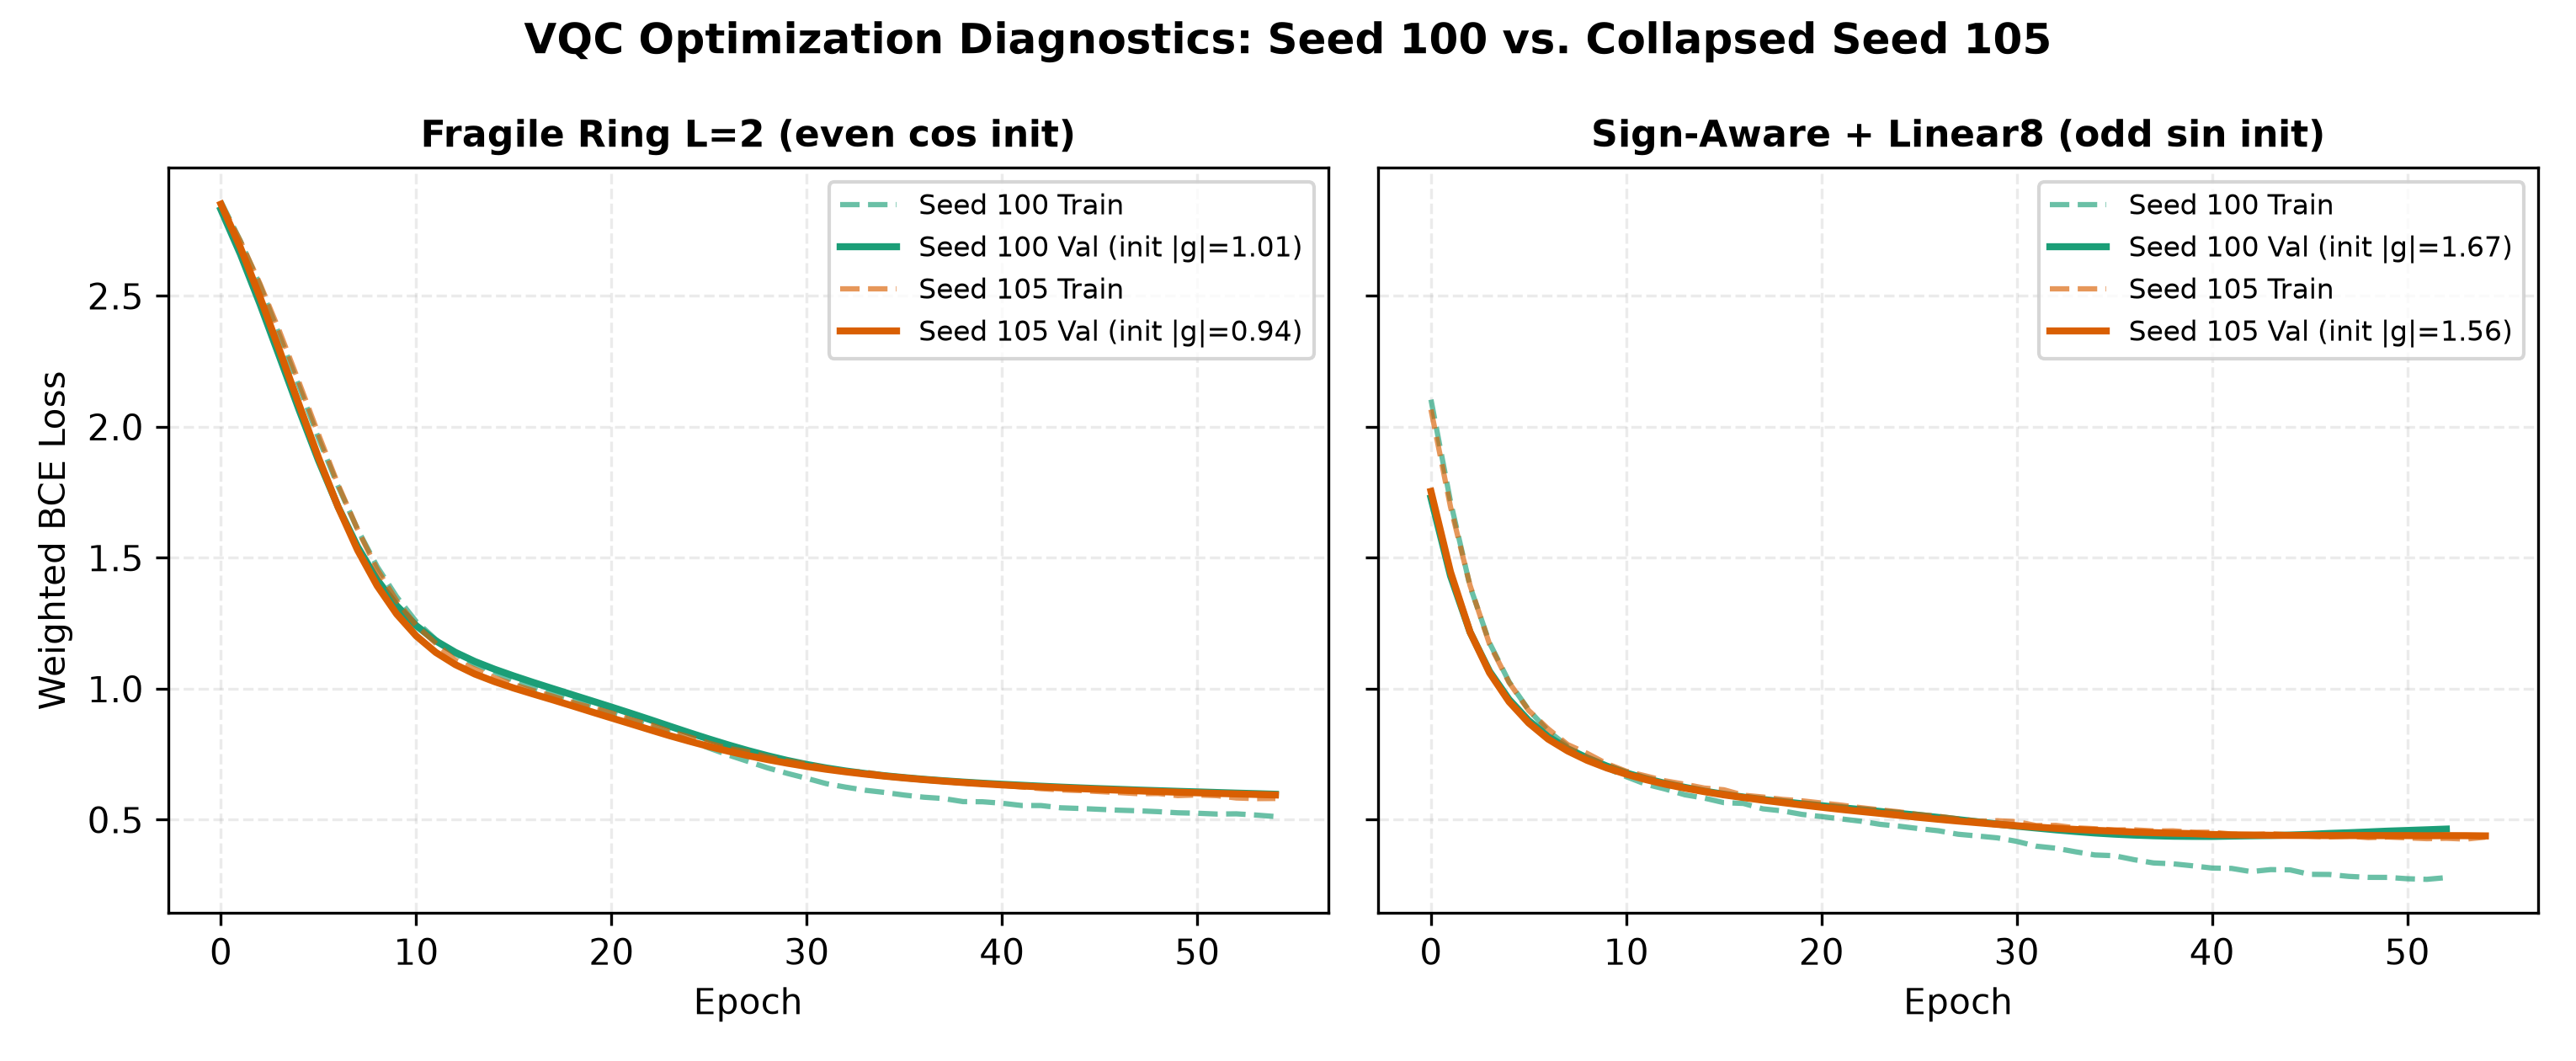

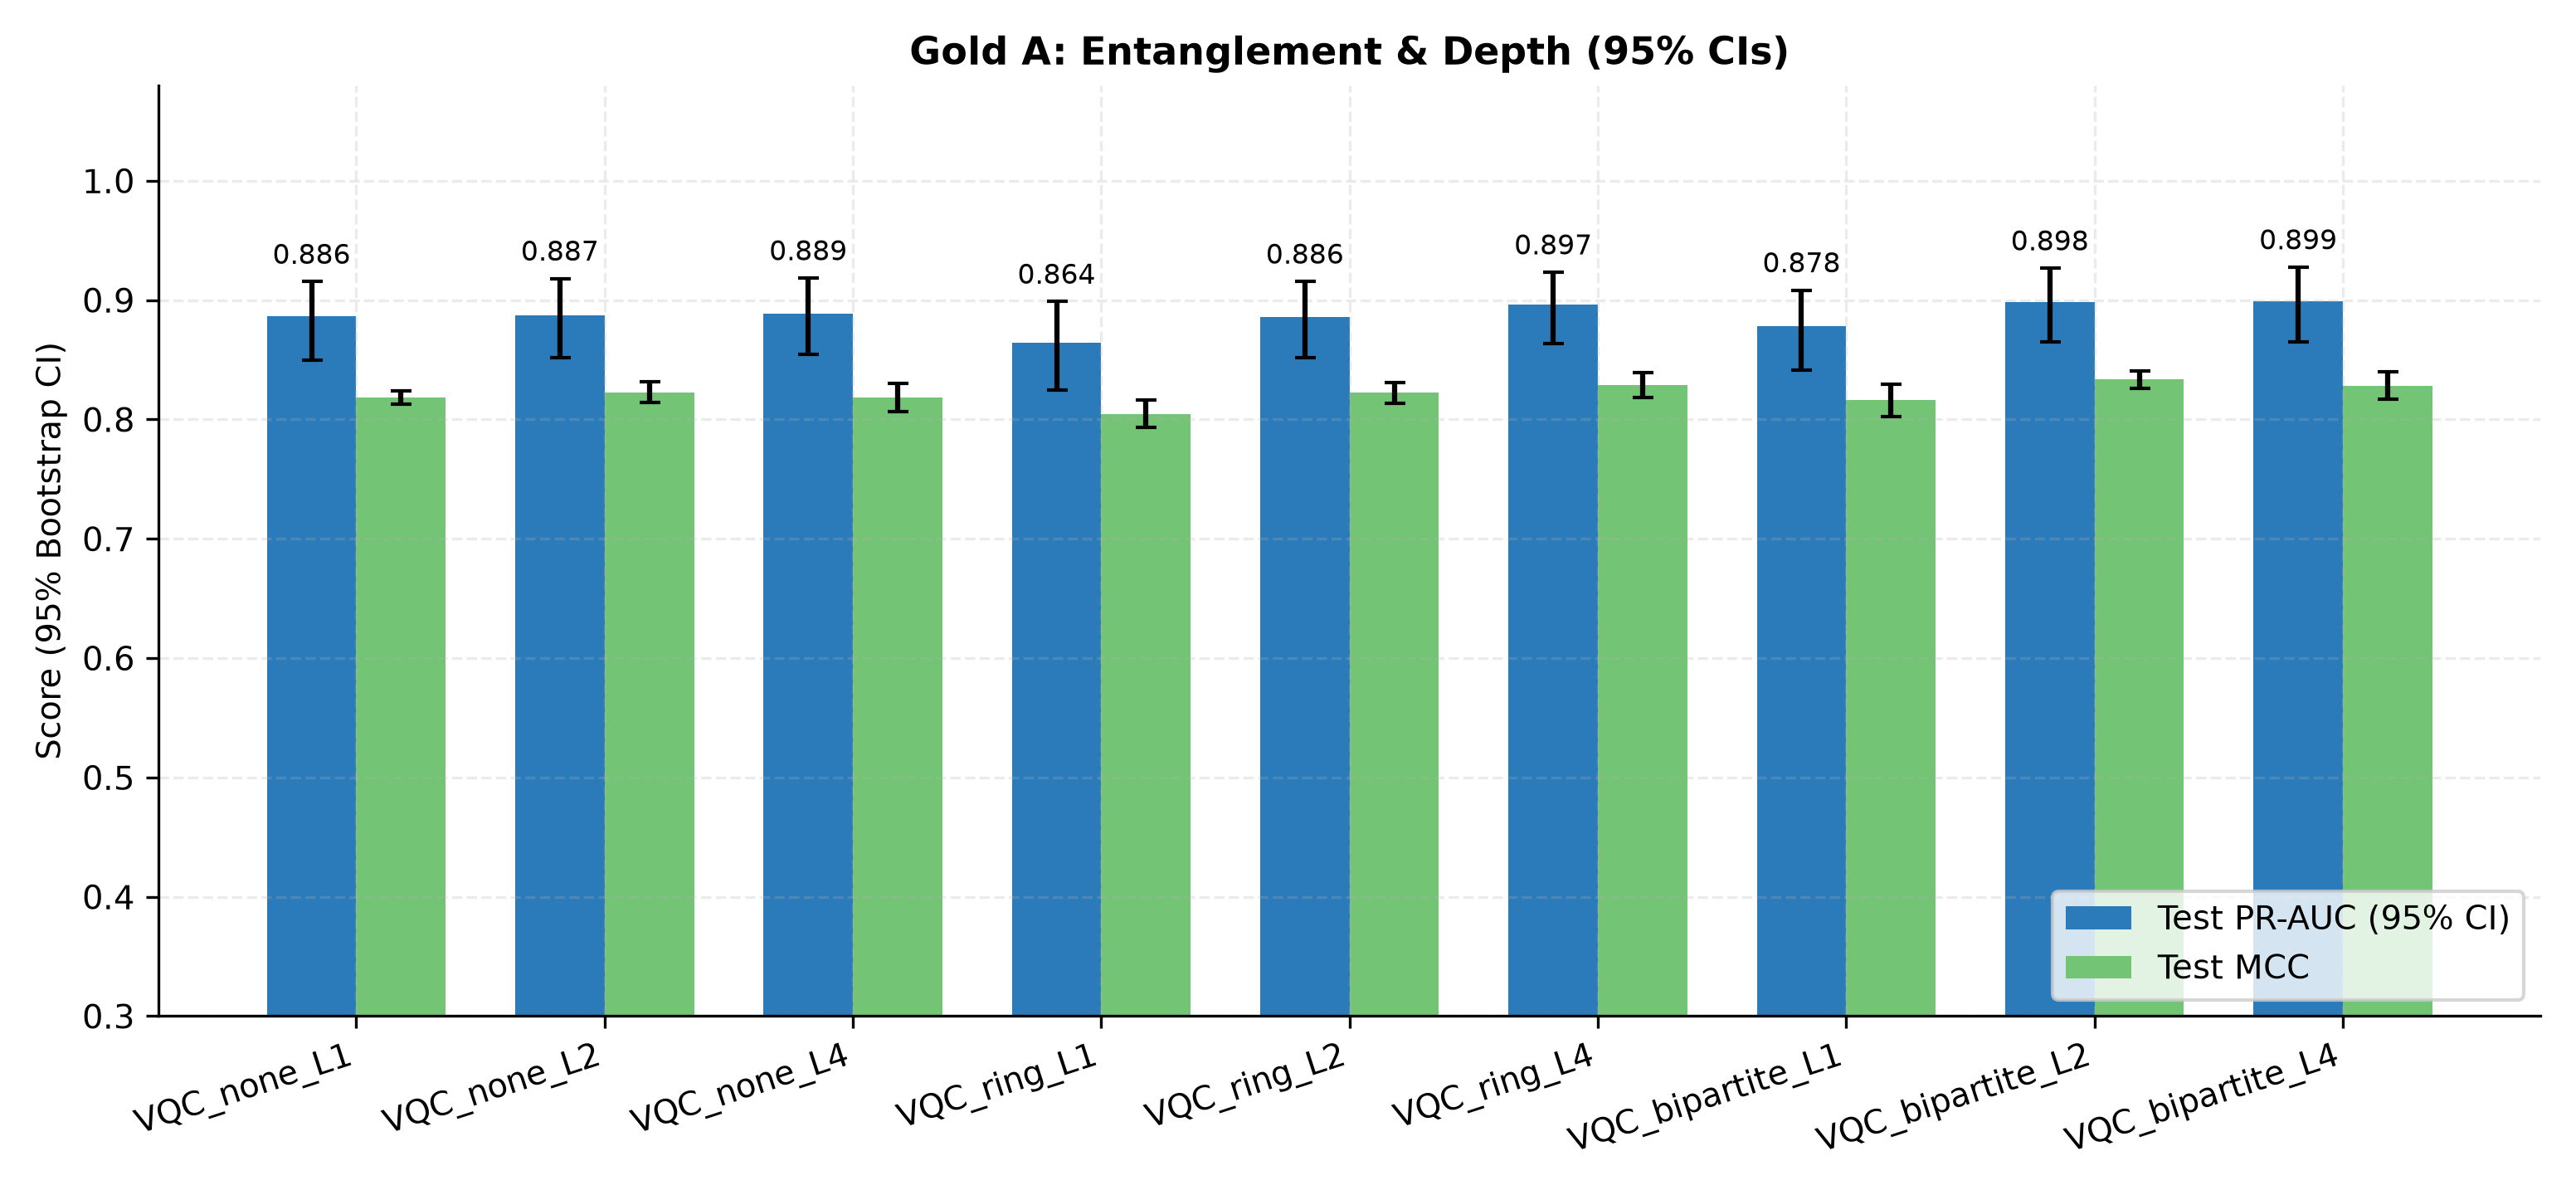

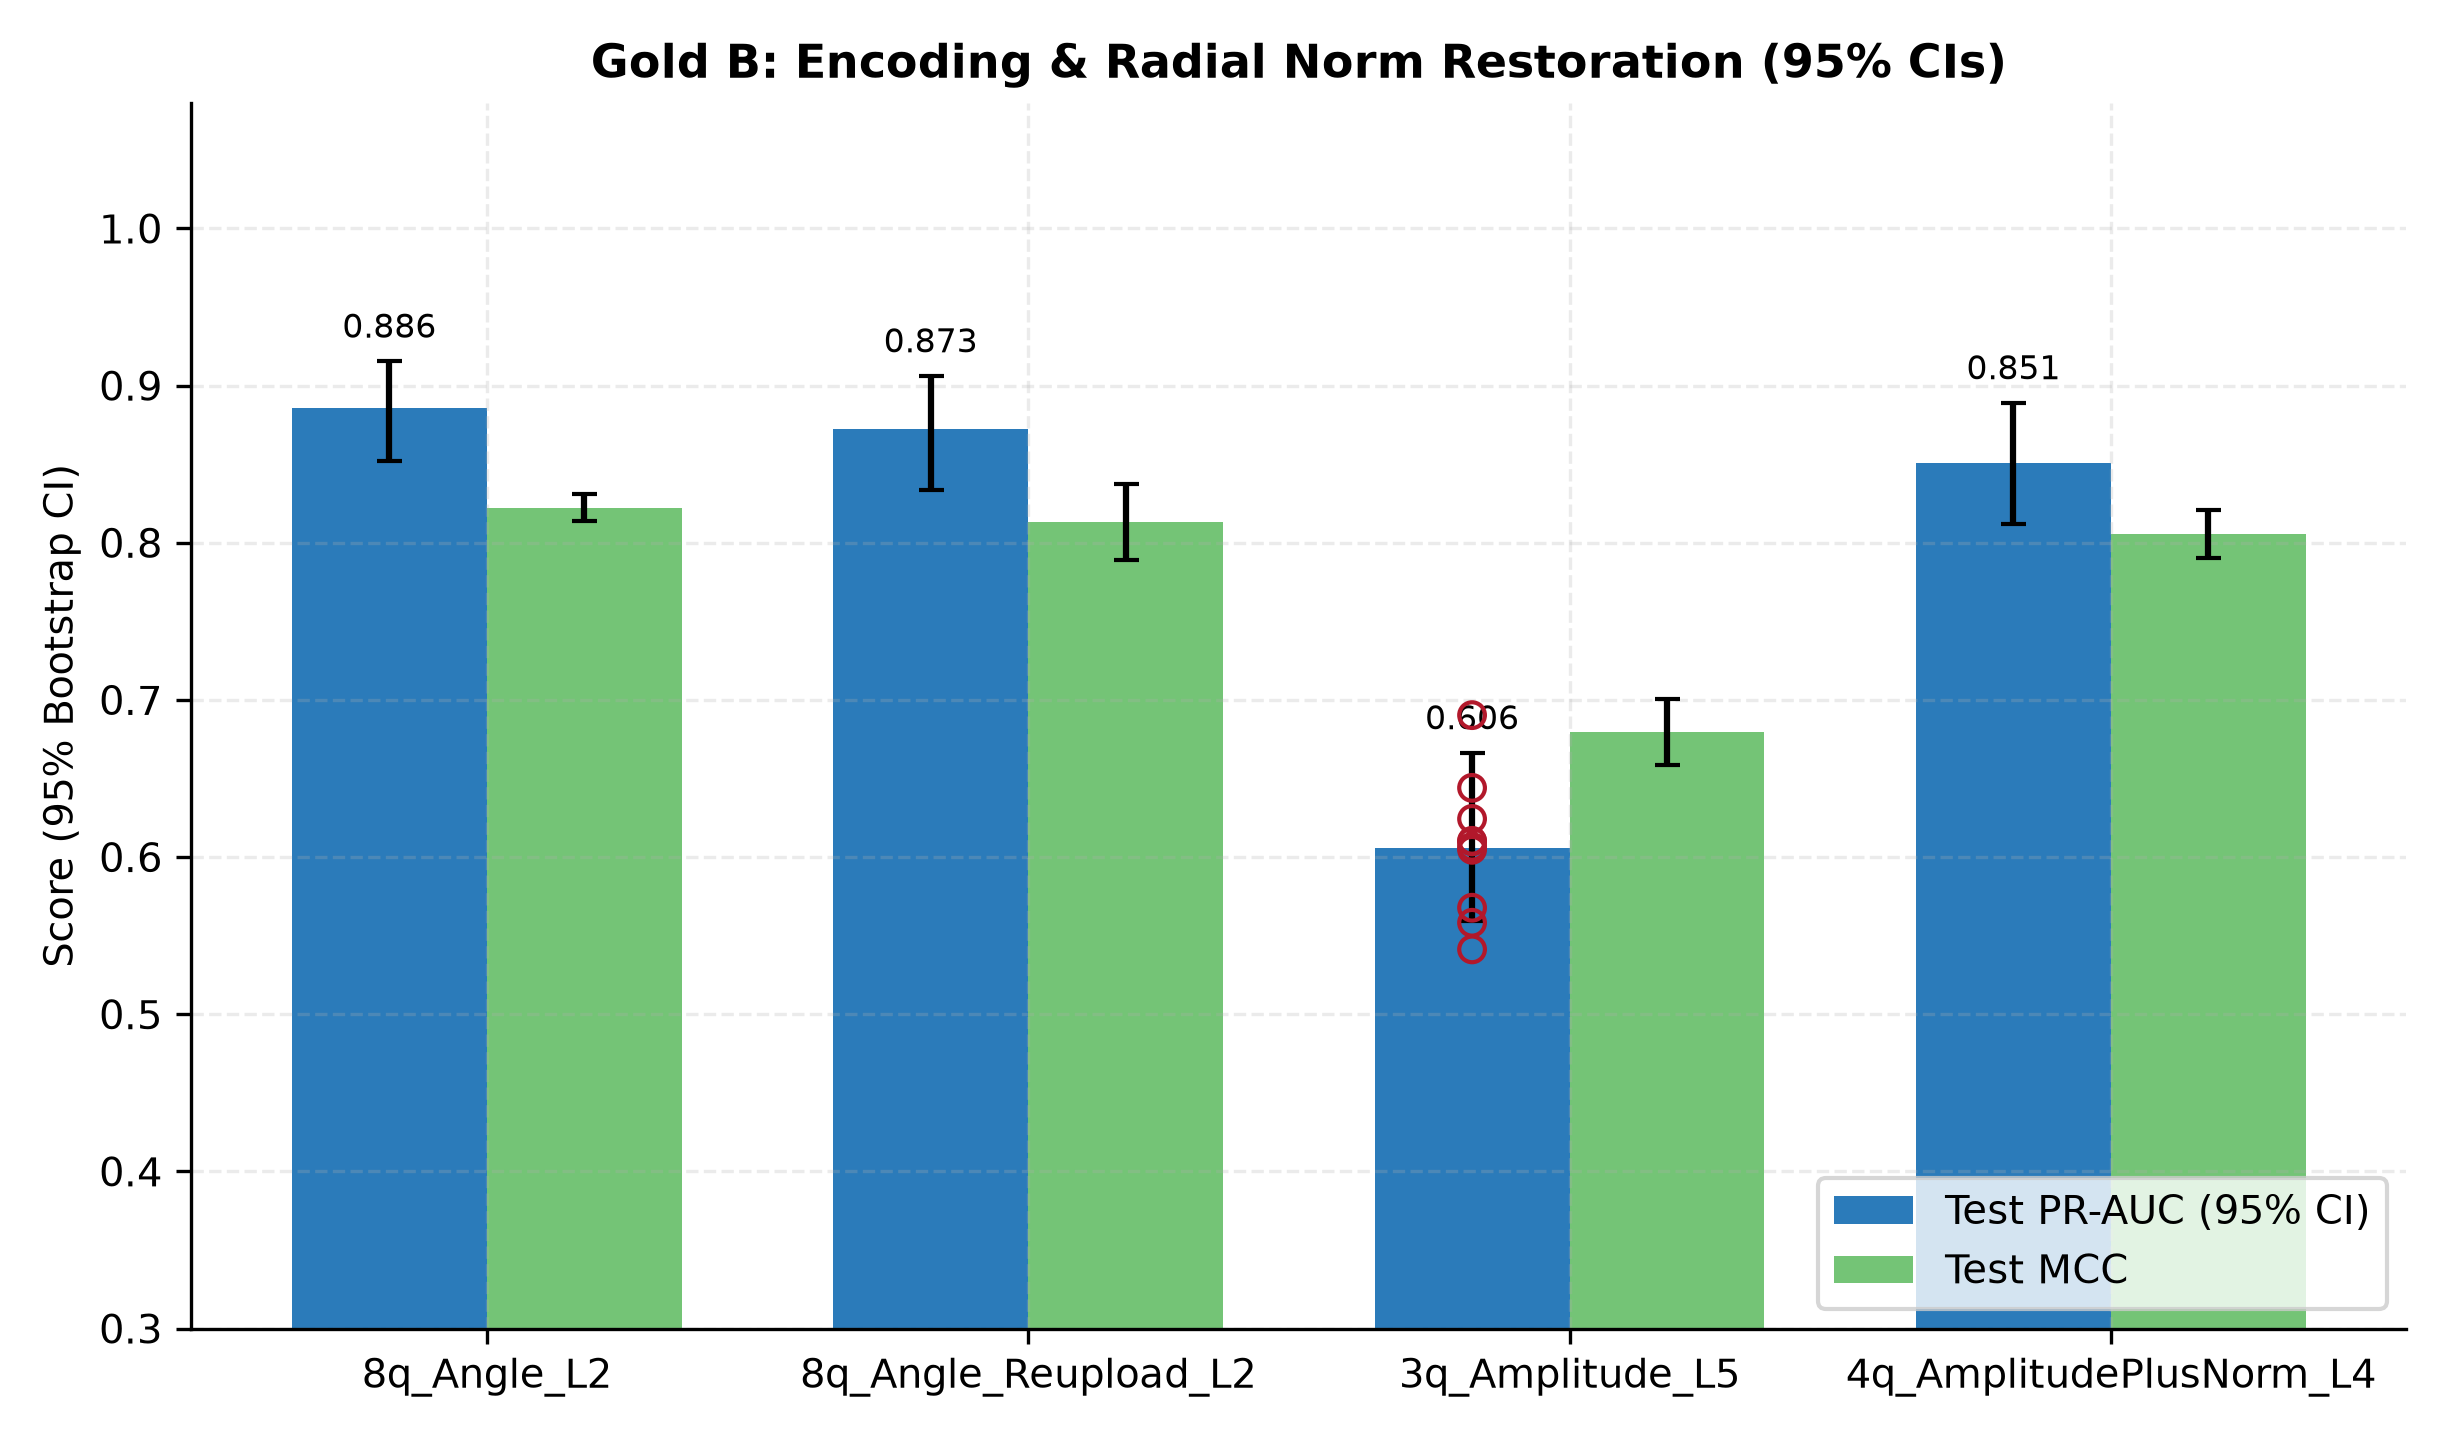

In [3]:
display(Markdown(Path("docs/vqc_stability.md").read_text(encoding="utf-8")))
display(Image(filename=str(RES_DIR / "vqc_loss_diagnostics.png")))
display(Image(filename=str(RES_DIR / "gold_a_entanglement.png")))
display(Image(filename=str(RES_DIR / "gold_b_encoding.png")))


## 3. Sample Efficiency & Finite Measurement Shot Noise


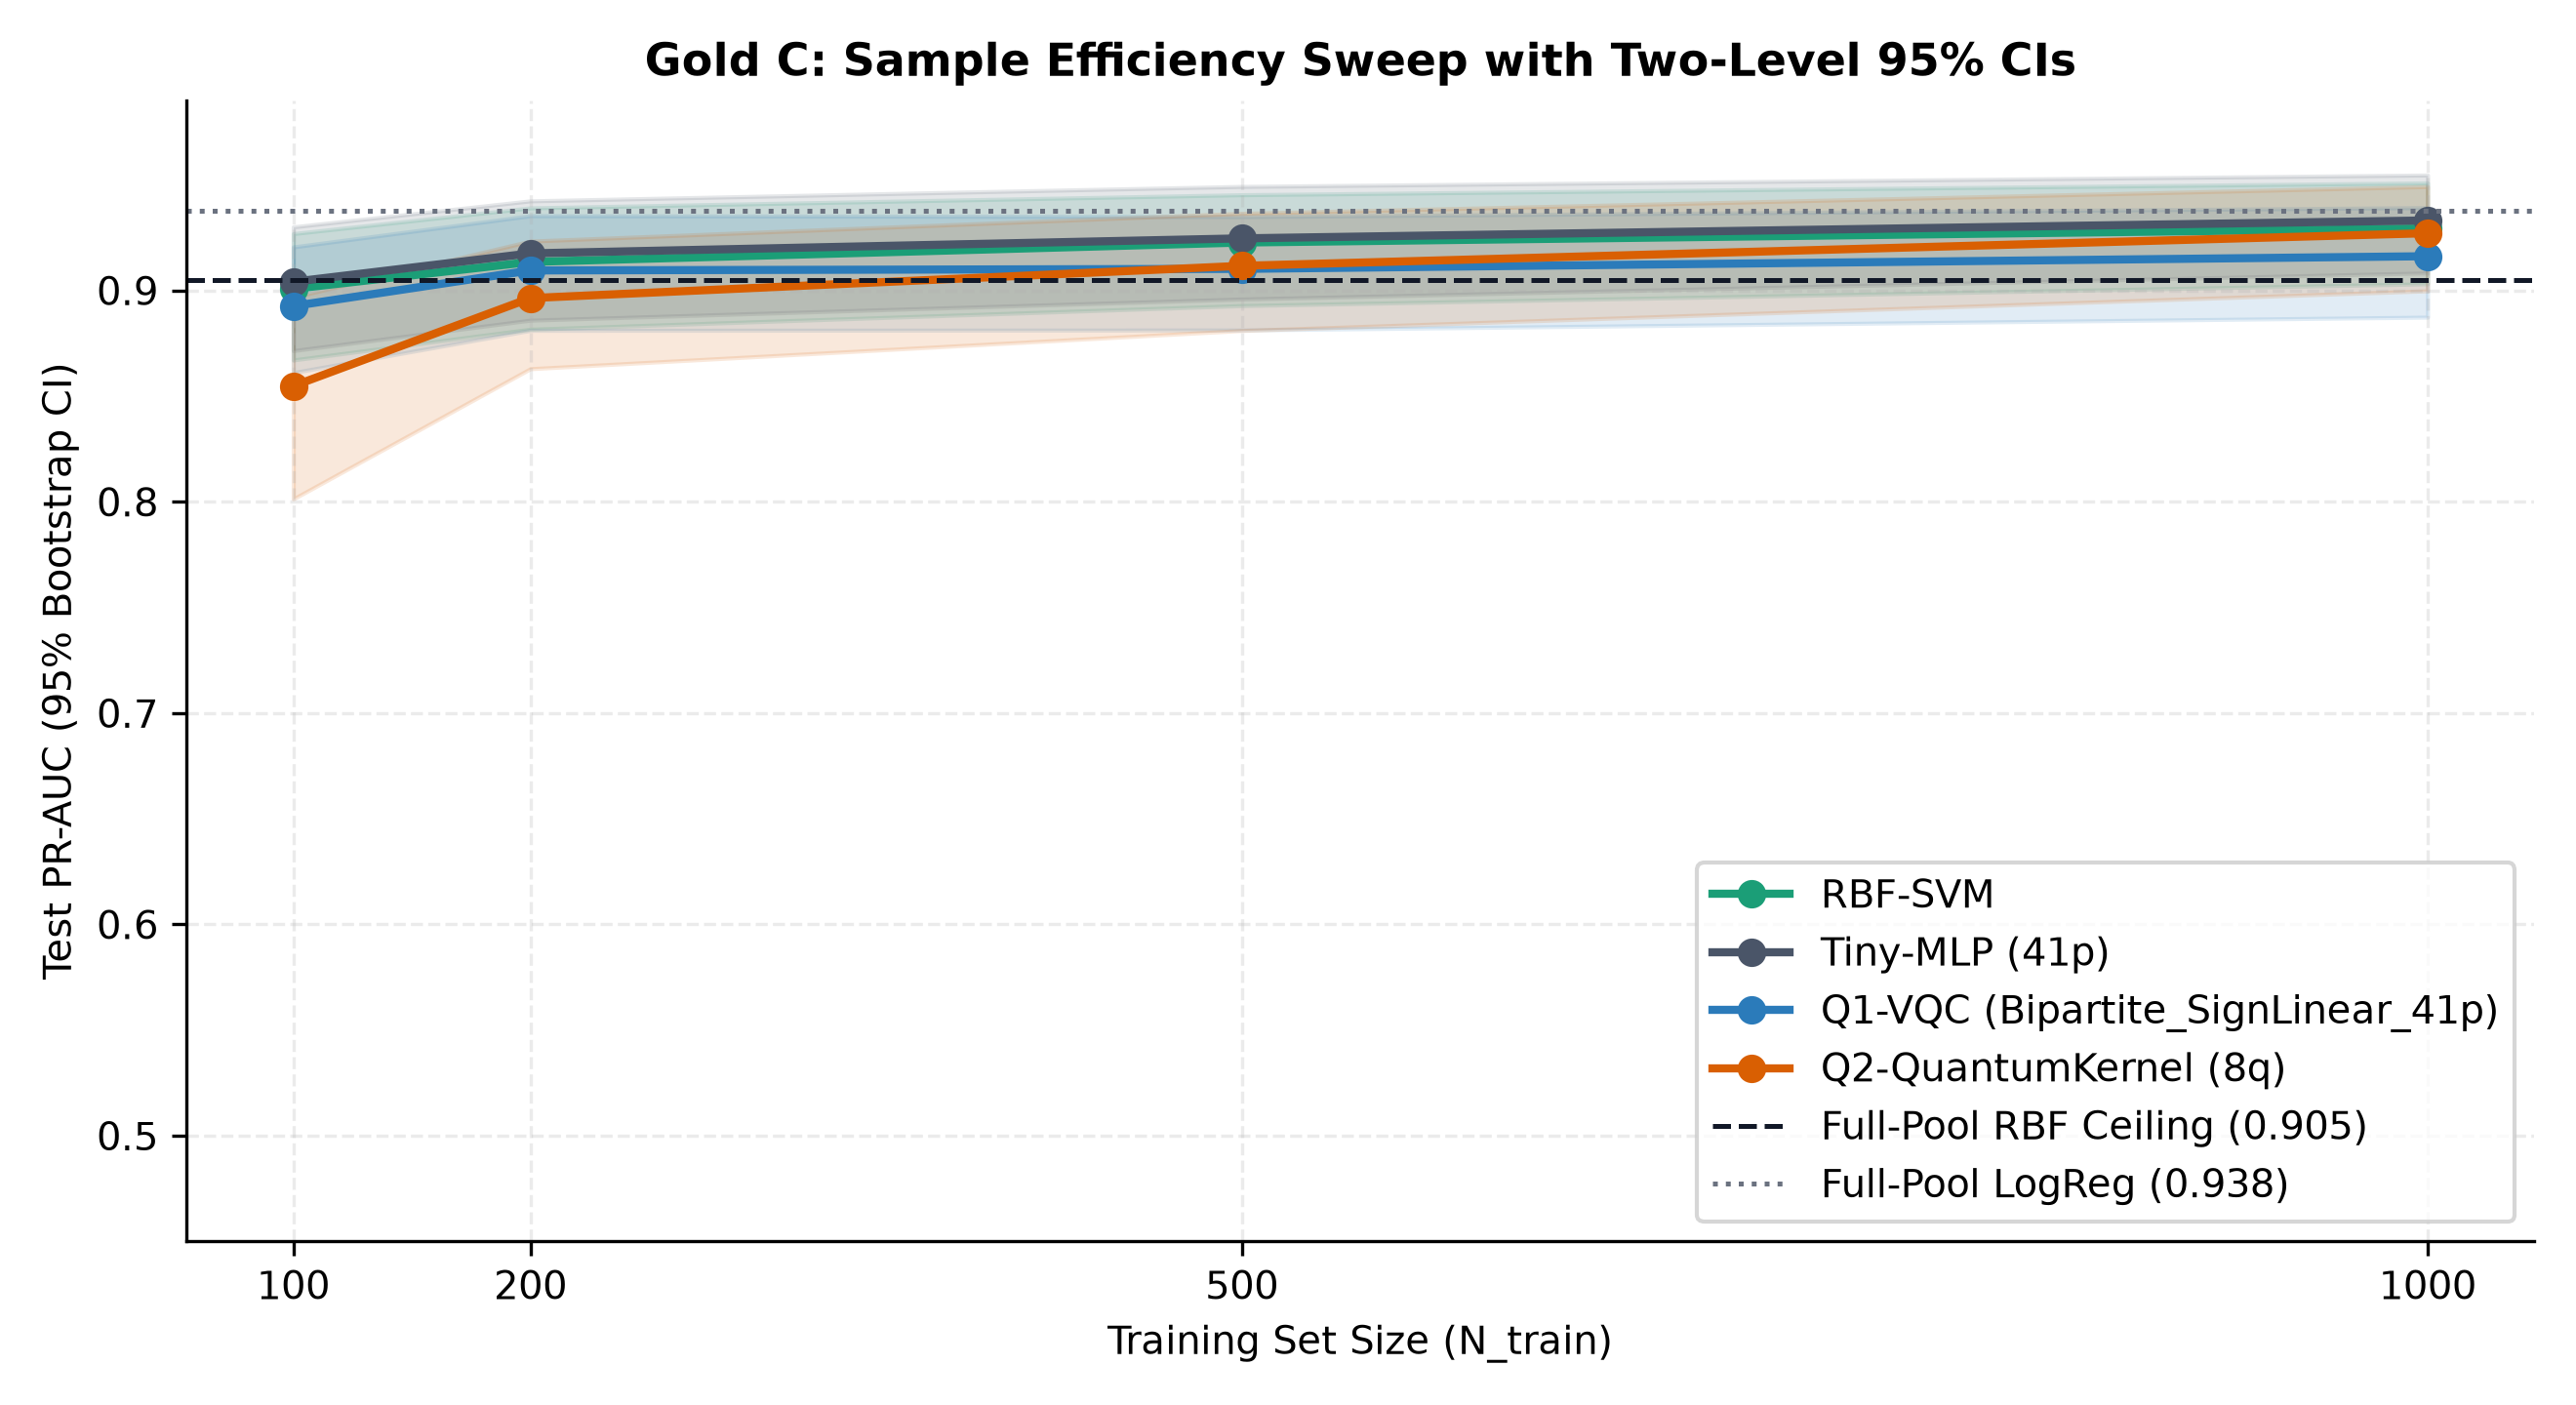

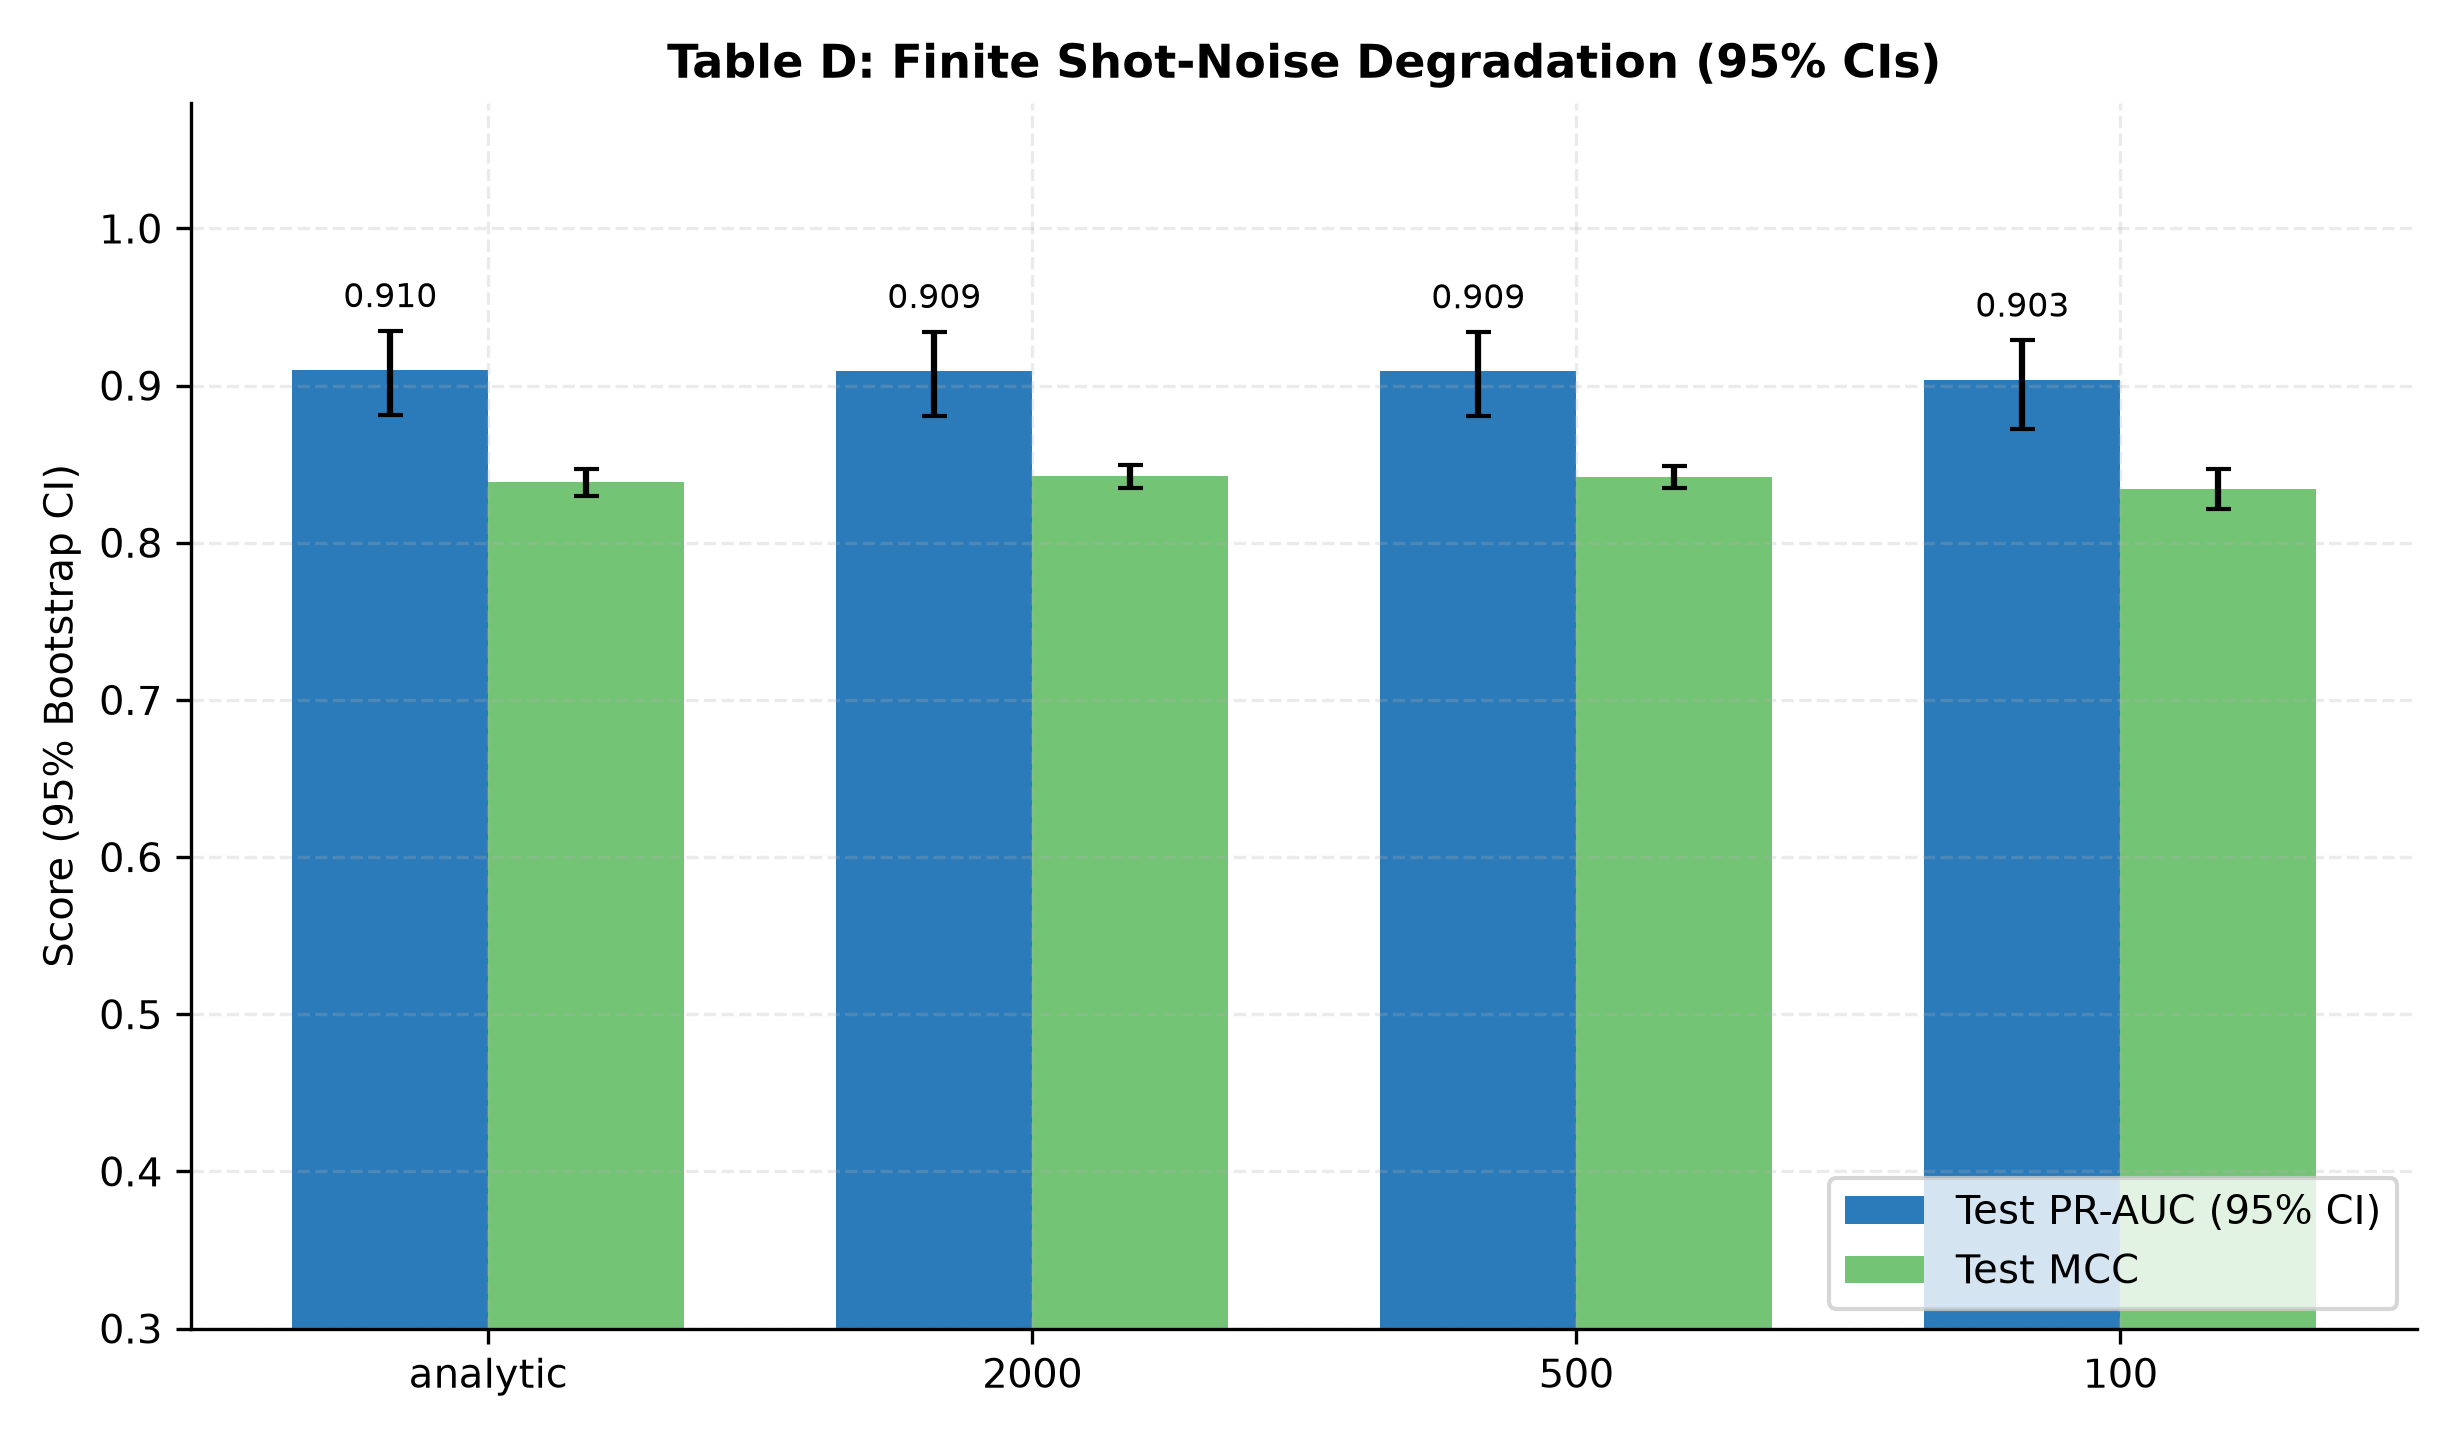

In [4]:
display(Image(filename=str(RES_DIR / "gold_c_sweep.png")))
display(Image(filename=str(RES_DIR / "table_d_shots.png")))


## 4. Depth of Insight: Linearity Ceiling, Kernel Geometry, Nonlinear 8D & Hardware Specs


# Phase 7 Depth-of-Insight Summary (`results/full`)

## 1. HTRU2 Near-Linear Separability & Full-Data Ceiling (`linearity_check.csv`)
Even on the full `13,398`-sample training pool, 9-parameter linear `LogReg` achieves `0.9378` PR-AUC versus `0.9050` for `RBF-SVM` (a gap of `-0.0328`). Because HTRU2 is nearly linearly separable after Yeo-Johnson standardization, any nonlinear feature map (quantum or classical) has less than `~0.01` PR-AUC headroom above a linear hyperplane.

## 2. Quantum Fidelity Kernel Geometry vs. Classical RBF (`kernel_analysis.csv`)
Across bandwidths `alpha in [0.1, 2.5]` and depths `1, 2`, the 8-qubit ZZ fidelity kernel peaks at `alpha = 0.1`, `depth = 1` (`test PR-AUC = 0.9199`, `KTA = 0.4261`, effective rank `1.8`, off-diagonal correlation `0.991` with tuned RBF-SVM `0.9255`). Larger `alpha` or deeper ZZ layers drive off-diagonal entries toward concentration (`mean -> 0.008`), shrinking kernel alignment and margin generalization.

## 3. Controlled Nonlinear 8D Benchmark (`nonlinear_dataset_summary.csv`)
Pre-screened with `RBF-SVM - LogReg = +0.7889 >= 0.05` at `N=500`, `ConcentricShell-8D` breaks linear `LogReg` (`0.1165` PR-AUC). Nonlinear models all separate the radial shell (`RBF-SVM = 0.8695`, `Tiny-MLP = 0.4075`, `Q2-QuantumKernel = 0.8832`, `Q1-VQC = 0.6602`), confirming that both quantum models capture genuine nonlinear structure when linear boundaries fail, though classical RBF-SVM/MLP remain stronger or faster in 8D.

## 4. Hardware Execution Cost & Classical Simulability (`hardware_cost_table.csv`)
Using `qml.specs`, `Q1-VQC` requires `O(N)` QPU executions (`3,000` test circuits), whereas `Q2-QuantumKernel` requires `124,750` training pairs (`O(N^2)`) plus `1,500,000` test pairs at `~10,000` shots/pair. At `<= 8` qubits (`dim <= 256`), all circuits are cheaply simulable on classical CPUs and **no quantum advantage is claimed**.


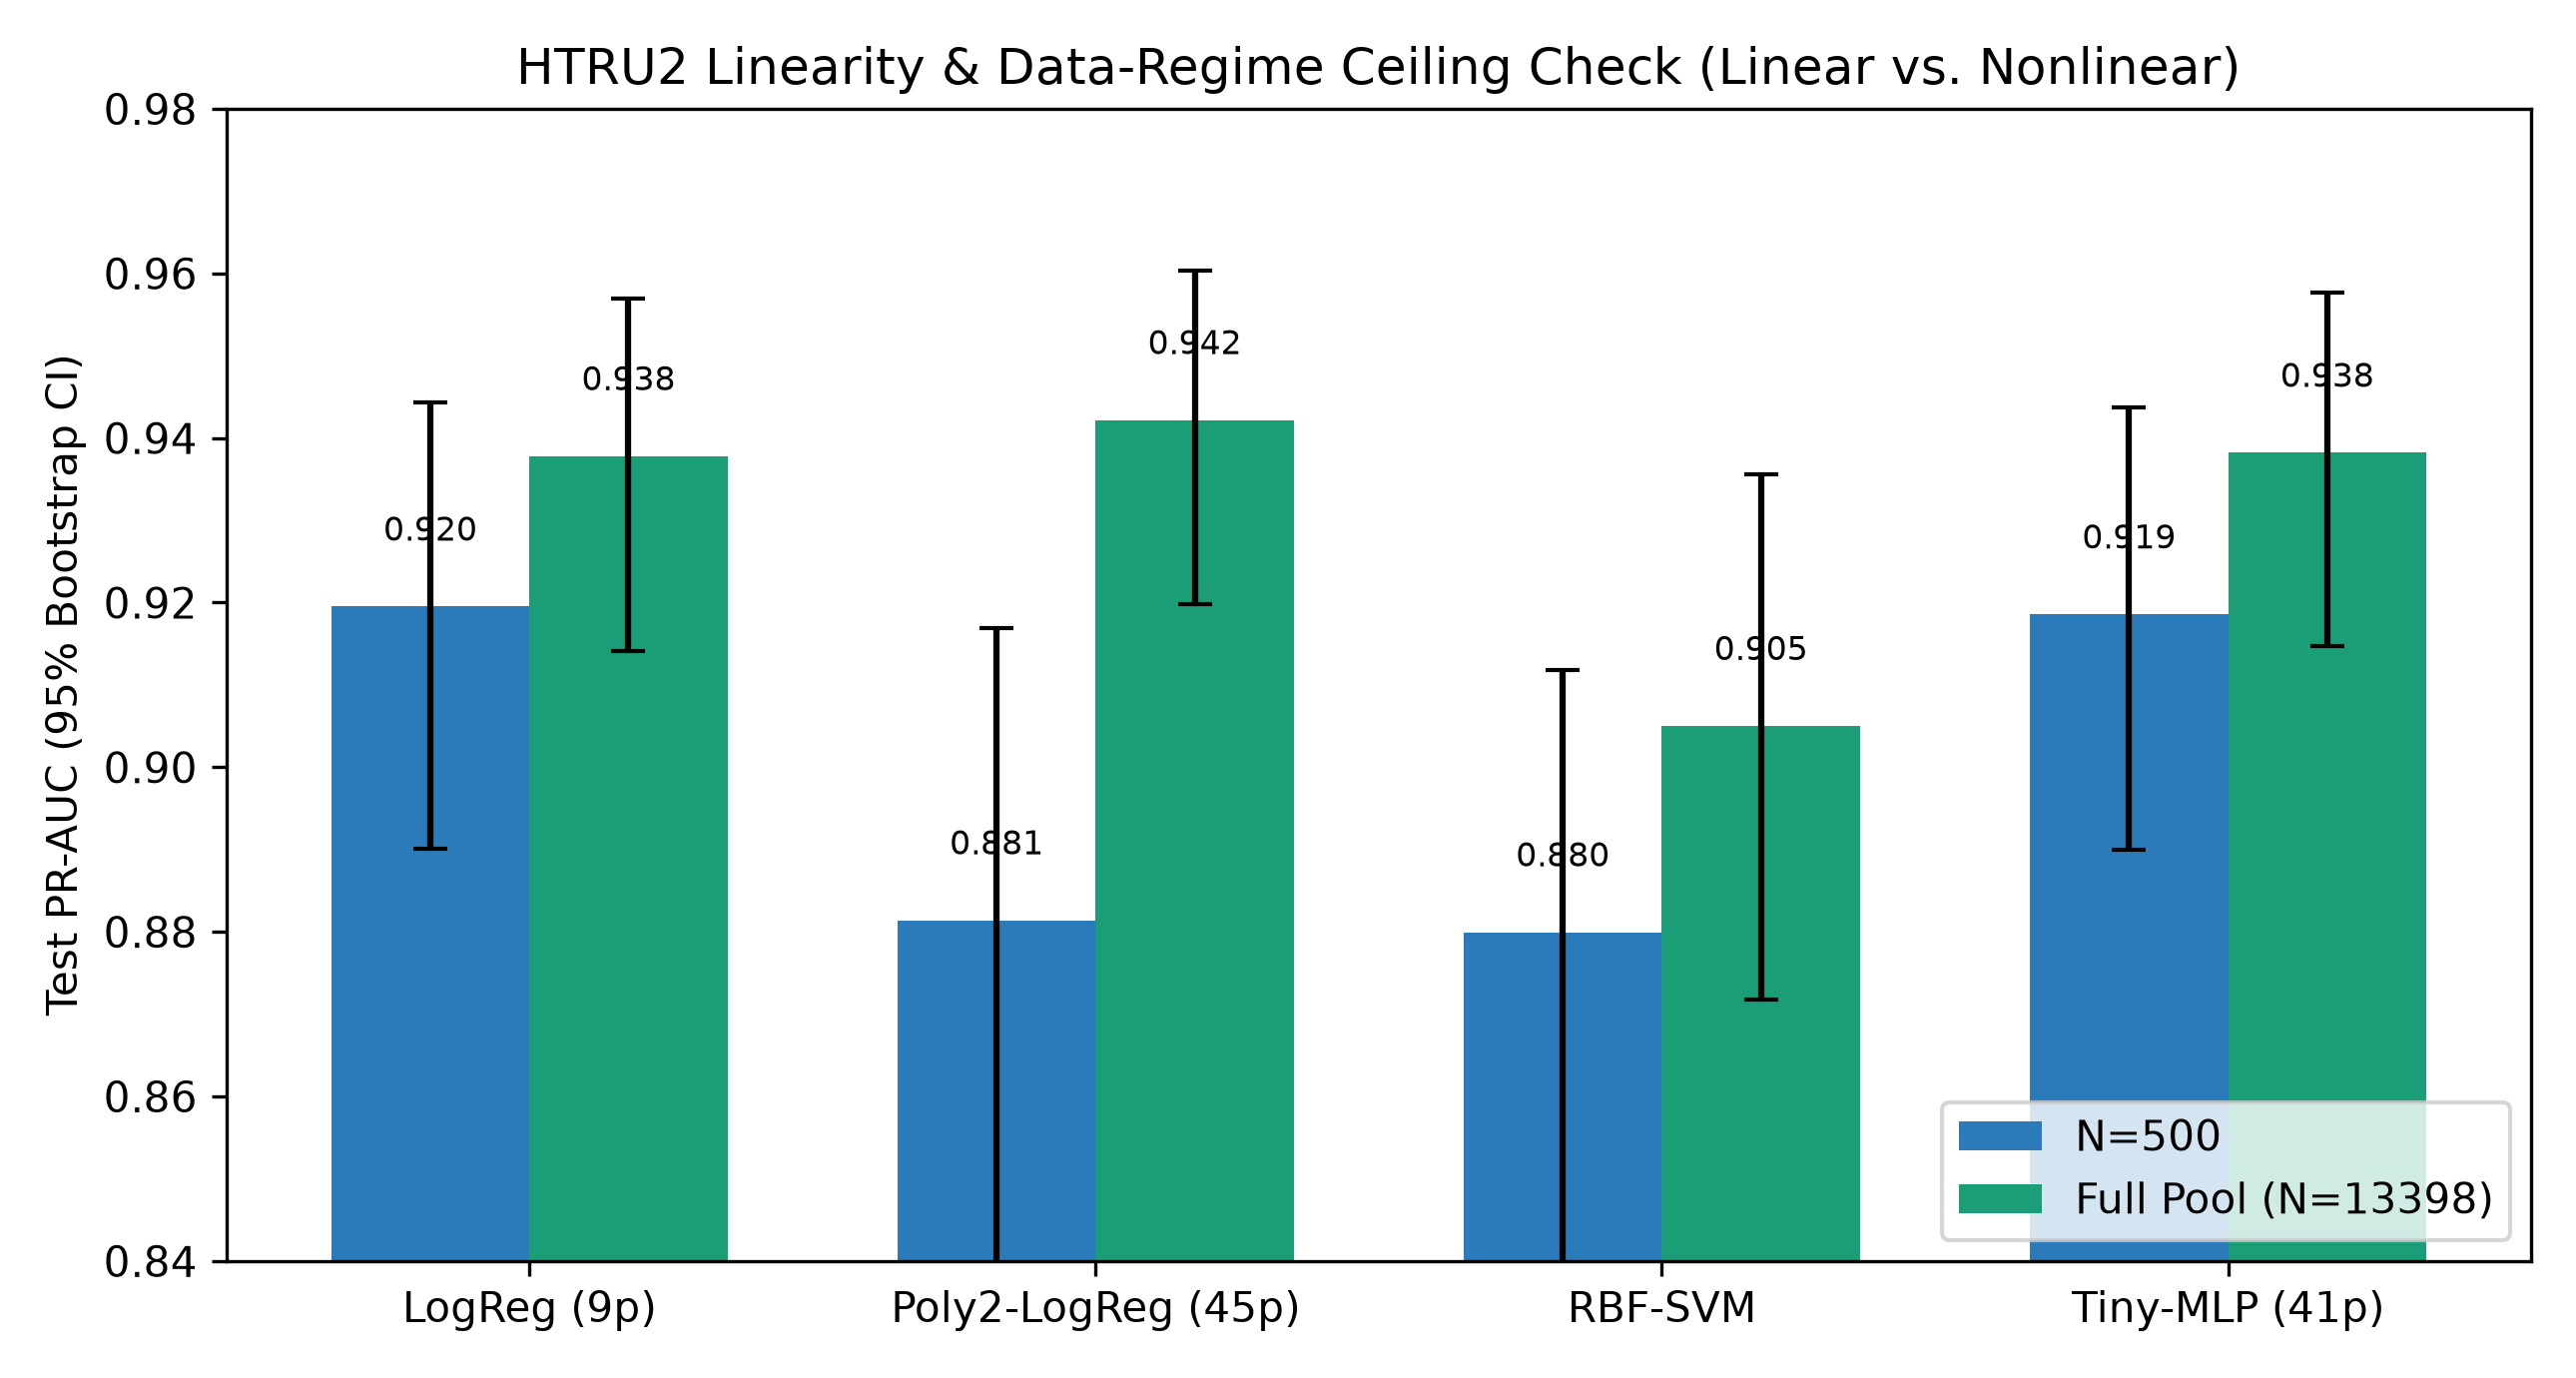

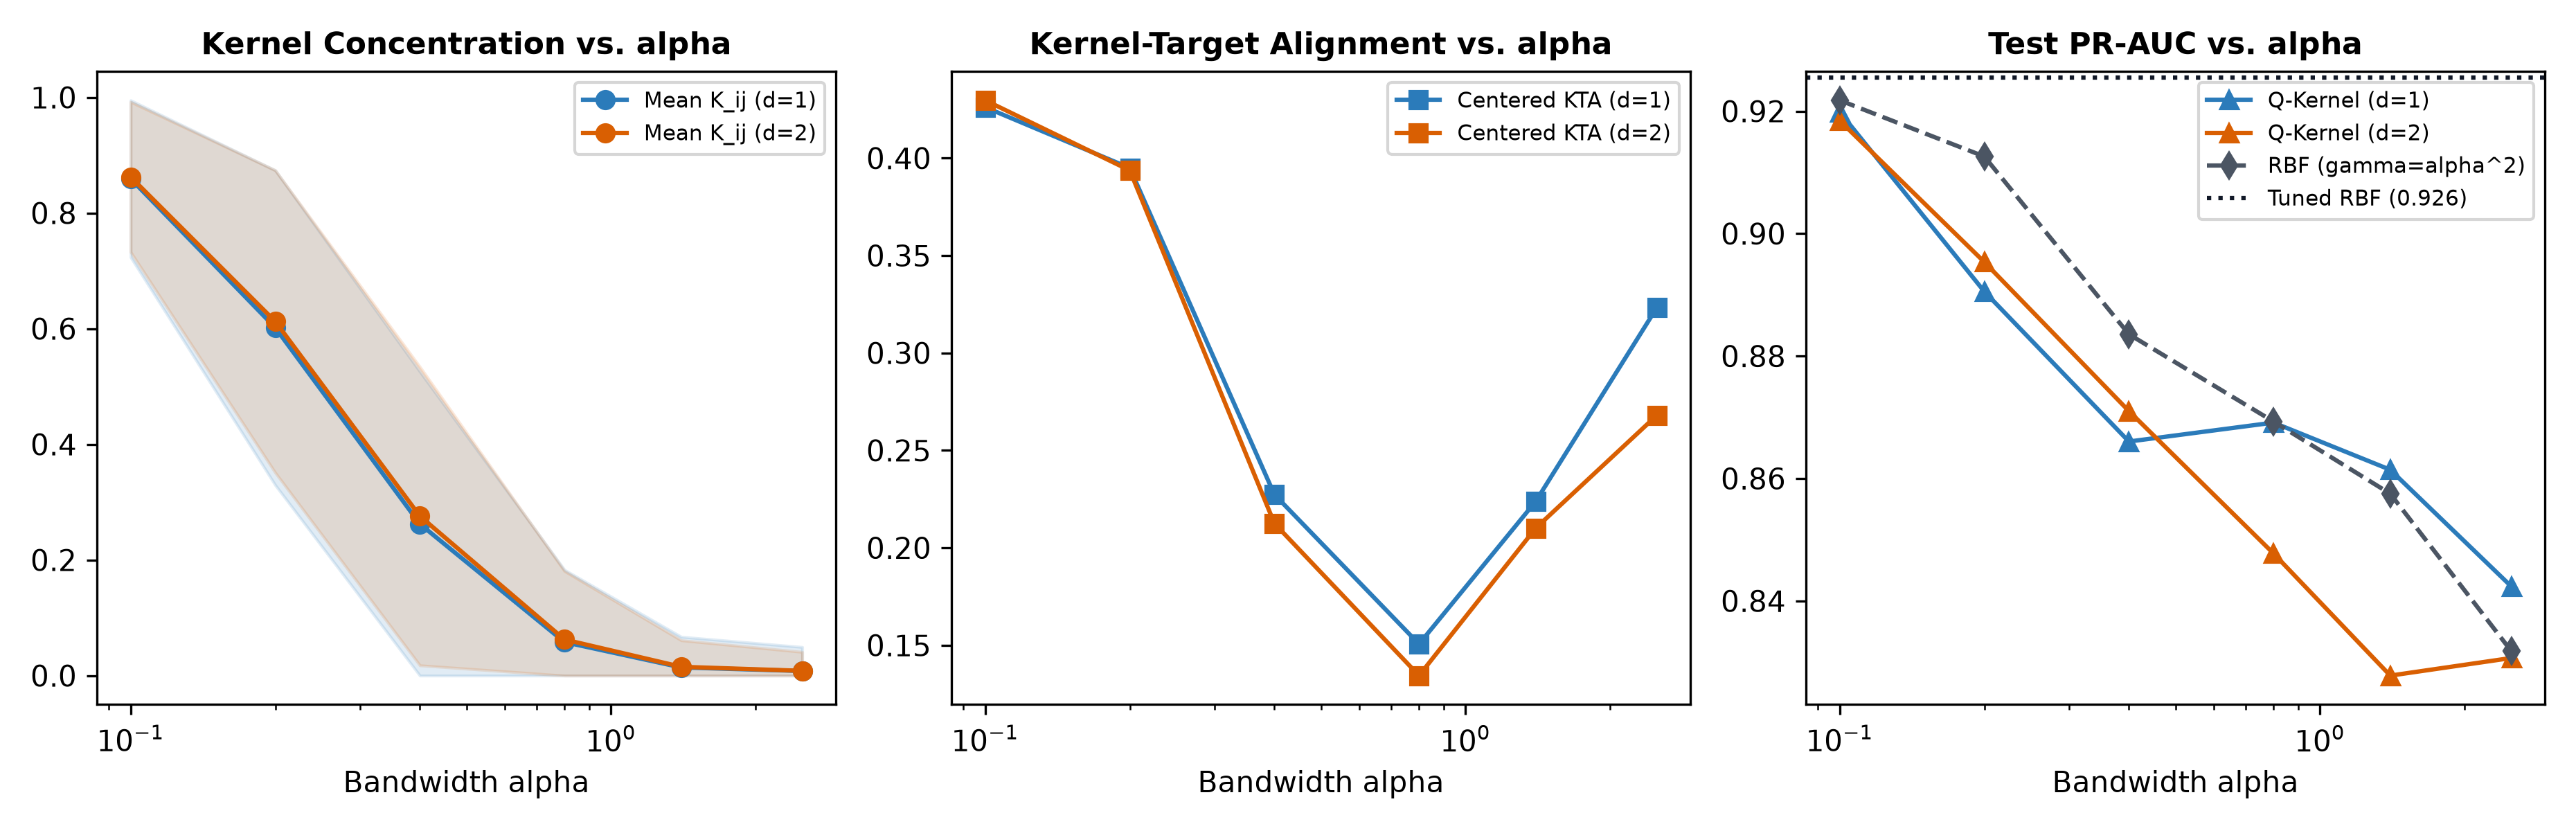

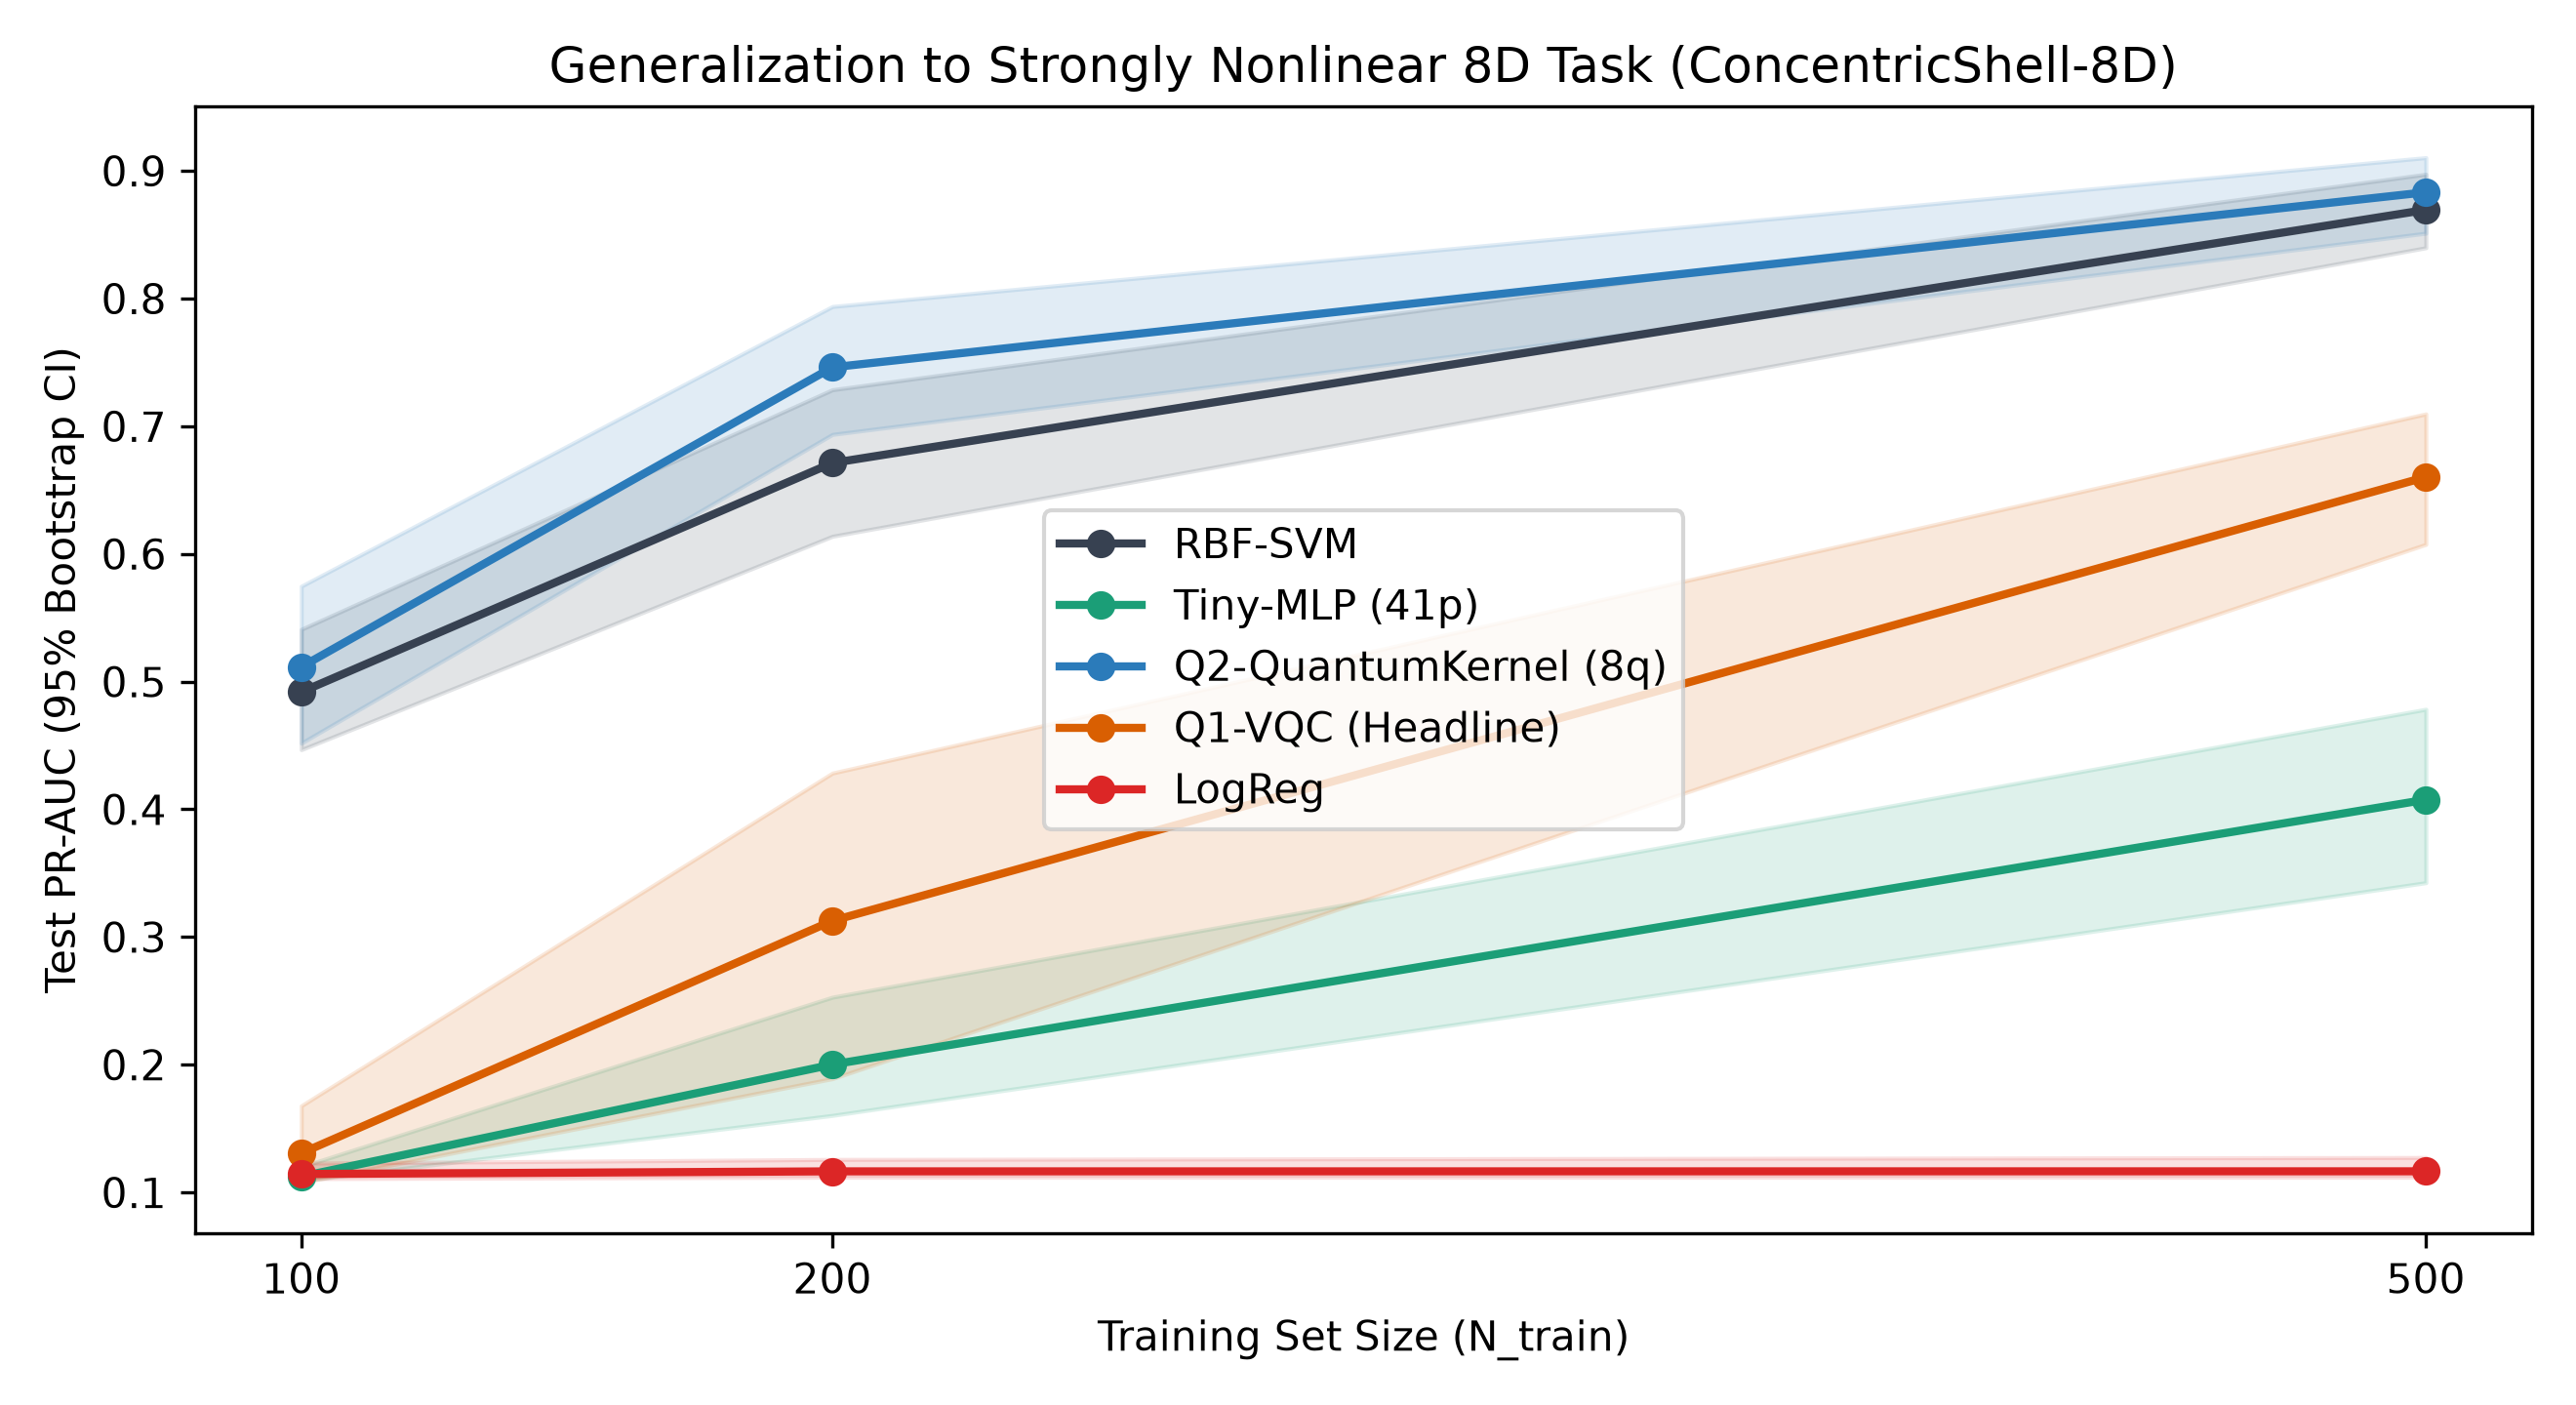

model,qubits,depth,total_gates,two_qubit_gates,trainable_params,qpu_circuits_train_N500,qpu_circuits_test_3000,shots_per_eval,simulability
"Q1-VQC (8q Bipartite Sign+Linear, 41p)",8,7,41,8,41,500/epoch (O(N)),"3,000 (O(N_test))","500-2,000 shots","<=8q (dim<=256), CPU-simulable"
"Q1-VQC (8q Ring L=2, 34p)",8,21,49,16,34,500/epoch (O(N)),"3,000 (O(N_test))","500-2,000 shots","<=8q (dim<=256), CPU-simulable"
"Q1-VQC (4q Amplitude+Norm L=4, 34p)",4,25,50,16,34,500/epoch (O(N)),"3,000 (O(N_test))","500-2,000 shots","<=8q (dim<=256), CPU-simulable"
"Q1-VQC (3q Amplitude L=5, 32p)",3,26,46,15,32,500/epoch (O(N)),"3,000 (O(N_test))","500-2,000 shots","<=8q (dim<=256), CPU-simulable"
"Q2-QuantumKernel (8q ZZ d=1, Inversion Test)",8,52,80,32,0,"124,750 pairs (N*(N-1)/2 = O(N^2))","1,500,000 pairs (N*N_test)","~10,000 shots/pair for +-0.01 K_ij","8q (dim=256), state-vector shortcut in sim"
RBF-SVM (Classical Reference),0,0,0,0,0,0 QPU runs,0 QPU runs,Exact float64,Classical baseline (no quantum advantage claimed)


In [5]:
display(Markdown(Path("docs/insights.md").read_text(encoding="utf-8")))
display(Image(filename=str(RES_DIR / "linearity_check.png")))
display(Image(filename=str(RES_DIR / "kernel_analysis.png")))
display(Image(filename=str(RES_DIR / "nonlinear_dataset.png")))
display(pd.read_csv(RES_DIR / "hardware_cost_table.csv"))
